# 01 · Challenge 1 — group formation

**Review claim (Bozdag et al., Fig. 2):** multicellular groups evolve *rapidly* and *convergently*
(e.g. 10/10 yeast populations under settling selection), usually through a single large-effect change
that repurposes existing machinery — e.g. loss of *ACE2*, so mother and daughter cells fail to separate
(snowflake yeast). Two routes exist: **clonal** (stay together after division) and **aggregative**
(come together); only the clonal route yields groups of close kin.

**How we get there from the minimal physical system.** Each cell is a small well-mixed reactor running the
Bunin–Rivoire chemistry (notebook 00); its stable state is its heritable composition. We add three
physical rules and nothing else:

1. **Growth** — a cell grows at a rate proportional to its catalytic activity (the paper's productivity),
   and divides at twice its birth mass. Daughters inherit the mother's concentrations.
2. **Separation is chemistry-dependent** — one species that is *active in the ancestor* (call it the
   "separase", like the ACE2 targets) is needed to cut the mother–daughter bond. If a noise-driven
   state switch turns it off, daughters stay bonded: a branching, snowflake-like cluster. Bonded cells
   exchange molecules by diffusion (paper App. D on a tree instead of a line). Very large clusters
   fracture under packing stress.
3. **An adhesin** — a species *inactive in the ancestor*; if a switch turns it on, the cell sticks to
   other sticky cells at the end of the day (aggregation).

There are no genes, templates or designed regulators: the "mutations" are the paper's noise-driven
jumps between stable states, and both multicellular phenotypes are read-outs of species that already
exist in the unicellular network.

**Experiment.** Serial transfer as in Ratcliff et al. (2012): grow for a day (~4.6 generations), then
transfer 10% of the biomass chosen by **settling** (bigger groups sink faster), by surviving
**predation** (small groups get eaten), or **at random** (control).

Run time: ~5–8 min on a 4-core laptop (`FAST = True`: ~3 min). Replicates run in parallel.

In [1]:
import os, time, warnings, numpy as np, matplotlib.pyplot as plt, networkx as nx
from protoevo import run_parallel
from nb1_model import setup_chemistry, run_one
os.makedirs('figures', exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
warnings.filterwarnings('ignore', category=RuntimeWarning)   # nan-means before groups exist
FAST = False
N_JOBS = None          # None = all cores but one; set 1 to run serially
REPS = 4 if FAST else 6
DAYS = 20 if FAST else 25
OMEGA = 0.14           # demographic noise per cell -> sets the mutation supply
t_start = time.time()

chem, anc, s0, roles = setup_chemistry(omega=OMEGA)
print('ancestral productivity P =', s0.mean().round(3), '| roles:', roles)

ancestral productivity P = 0.433 | roles: {'sep': 20, 'sep_partner': 11, 'adh': 15, 'adh_rep': 17}


## The ancestral cell's network
Black = active species in the ancestral stable state. The separase (red) is active and is the *only*
active repressor of one neighbour, so a single noise-driven dip lets that neighbour switch on and the
separase off — a one-step, loss-of-function-like change. The adhesin (blue) is inactive and has a
single active repressor, so it is one step from switching on.

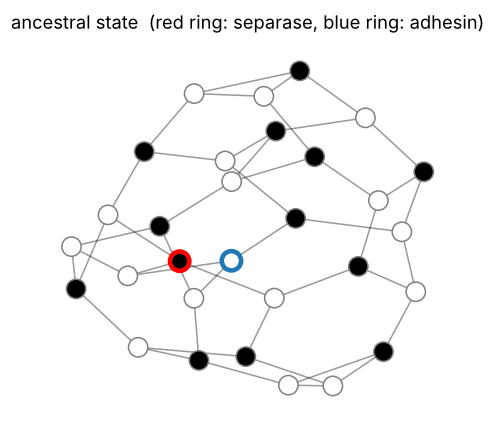

In [2]:
pos = nx.kamada_kawai_layout(chem.G)
col = ['black' if s0[i] else 'white' for i in range(chem.N)]
ec = ['red' if i == roles['sep'] else 'tab:blue' if i == roles['adh'] else 'gray' for i in range(chem.N)]
lw = [3 if i in (roles['sep'], roles['adh']) else 1 for i in range(chem.N)]
plt.figure(figsize=(5, 4.5))
nx.draw_networkx_edges(chem.G, pos, alpha=.4)
nx.draw_networkx_nodes(chem.G, pos, node_color=col, edgecolors=ec, linewidths=lw, node_size=160)
plt.title('ancestral state  (red ring: separase, blue ring: adhesin)'); plt.axis('off')
plt.savefig('figures/01_network.png'); plt.show()

## Replicate evolution experiments

In [3]:
conditions = [('settle', 'clonal'), ('predation', 'clonal'), ('none', 'clonal'),
              ('settle', 'aggregative'), ('predation', 'aggregative'), ('none', 'aggregative')]
jobs = [dict(omega=OMEGA, days=DAYS, selection=sel, route=route, seed=100 + r, record_states=True)
        for sel, route in conditions for r in range(REPS)]
out = run_parallel(run_one, jobs, N_JOBS)
results = {c: out[i * REPS:(i + 1) * REPS] for i, c in enumerate(conditions)}
gpd = out[0]['gen_per_day']
print(f'{len(jobs)} populations simulated in {time.time() - t_start:.0f} s')

36 populations simulated in 586 s


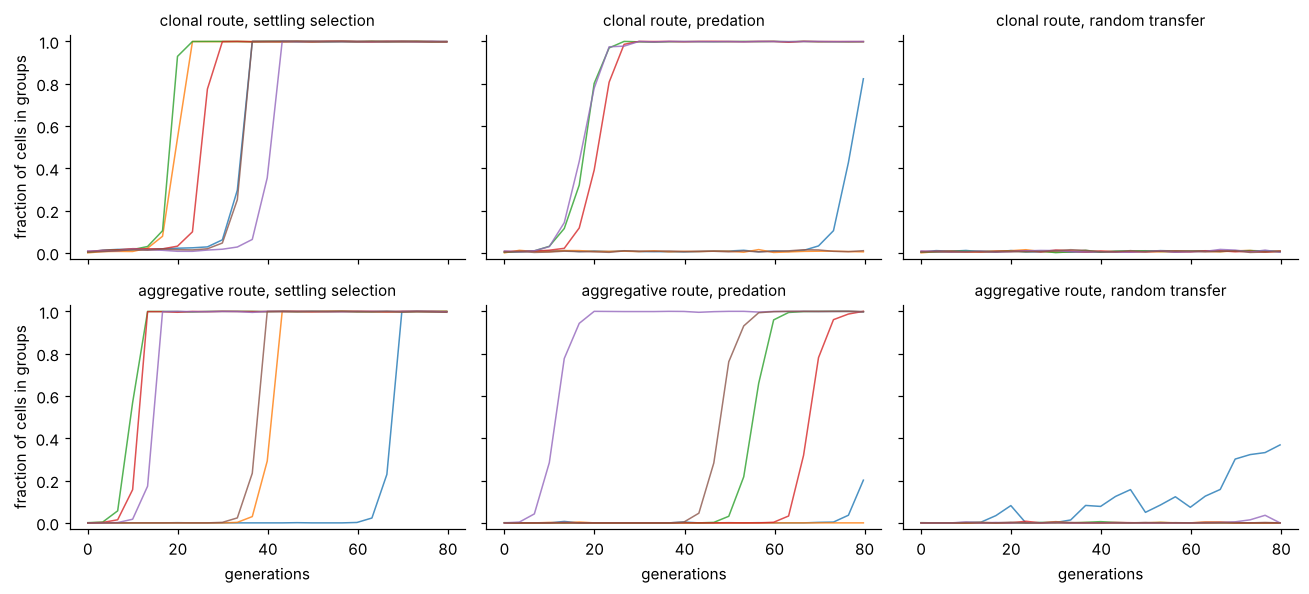

In [4]:
fig, ax = plt.subplots(2, 3, figsize=(12, 5.5), sharex=True, sharey=True)
gens = np.arange(DAYS) * gpd
for k, c in enumerate(conditions):
    a = ax[k // 3, k % 3]
    for h in results[c]:
        a.plot(gens, h['frac_multi'], lw=1, alpha=.8)
    sel_name = {'settle': 'settling selection', 'predation': 'predation', 'none': 'random transfer'}[c[0]]
    a.set_title(f'{c[1]} route, {sel_name}', fontsize=10); a.set_ylim(-0.03, 1.03)
for a in ax[1]: a.set_xlabel('generations')
for a in ax[:, 0]: a.set_ylabel('fraction of cells in groups')
plt.tight_layout(); plt.savefig('figures/01_timecourses.png'); plt.show()

## Rapid and convergent — the Fig. 2c summary
A population "evolved multicellularity" when more than half its cells are in groups at the end of a day.

In [5]:
def origin_time(h, thr=0.5):
    i = np.nonzero(h['frac_multi'] > thr)[0]
    return i[0] * gpd if len(i) else np.nan

print(f"{'condition':32s} evolved   mean generations   final mean group size (cell-weighted)")
summary = {}
for c in conditions:
    t = np.array([origin_time(h) for h in results[c]])
    sz = np.mean([h['mean_size'][-1] for h in results[c]])
    summary[c] = (np.sum(~np.isnan(t)), np.nanmean(t) if np.any(~np.isnan(t)) else np.nan)
    print(f'{c[1] + " / " + c[0]:32s} {summary[c][0]}/{REPS}       {summary[c][1]:6.1f}            {sz:6.1f}')

condition                        evolved   mean generations   final mean group size (cell-weighted)
clonal / settle                  6/6         30.5              22.2
clonal / predation               4/6         35.7              14.5
clonal / none                    0/6          nan               1.0
aggregative / settle             6/6         32.1               8.0
aggregative / predation          4/6         47.3               5.9
aggregative / none               0/6          nan               1.4


## Clonal versus aggregative groups: who is in the group?
A neutral marker mutates at 5% of divisions, so it records recent common descent. Clonal clusters are
made of close kin; aggregates are as related as two random cells of the population.

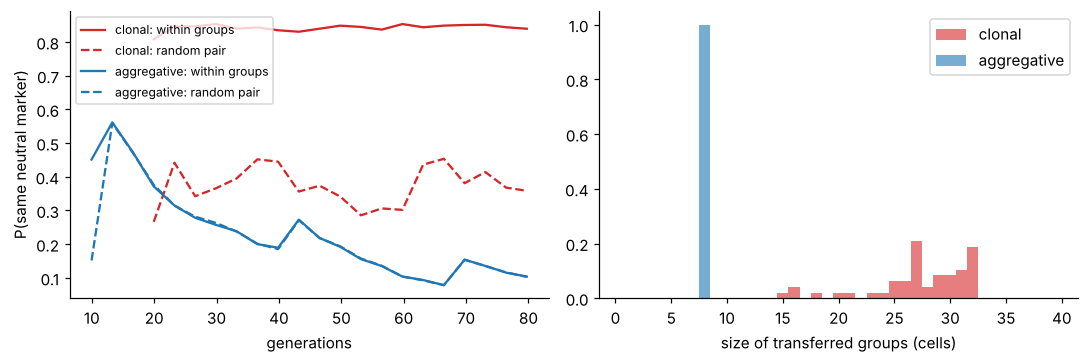

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for c, colr in [(('settle', 'clonal'), 'tab:red'), (('settle', 'aggregative'), 'tab:blue')]:
    rel = np.array([h['relatedness'] for h in results[c]]); bg = np.array([h['rel_background'] for h in results[c]])
    ok = np.array([h['frac_multi'] > 0.5 for h in results[c]])
    ax[0].plot(gens, np.nanmean(np.where(ok, rel, np.nan), 0), c=colr, label=f'{c[1]}: within groups')
    ax[0].plot(gens, np.nanmean(np.where(ok, bg, np.nan), 0), c=colr, ls='--', label=f'{c[1]}: random pair')
ax[0].set_xlabel('generations'); ax[0].set_ylabel('P(same neutral marker)'); ax[0].legend(fontsize=8)
for c, colr in [(('settle', 'clonal'), 'tab:red'), (('settle', 'aggregative'), 'tab:blue')]:
    sizes = np.concatenate([np.bincount(np.unique(h['final_grp'], return_inverse=True)[1]) for h in results[c]])
    ax[1].hist(sizes, bins=np.arange(0.5, 40, 1), alpha=.6, color=colr, label=c[1], density=True)
ax[1].set_xlabel('size of transferred groups (cells)'); ax[1].legend()
plt.tight_layout(); plt.savefig('figures/01_relatedness.png'); plt.show()

## One evolved snowflake cluster
The bond tree of the largest group in one settling-selected population (each node a cell).

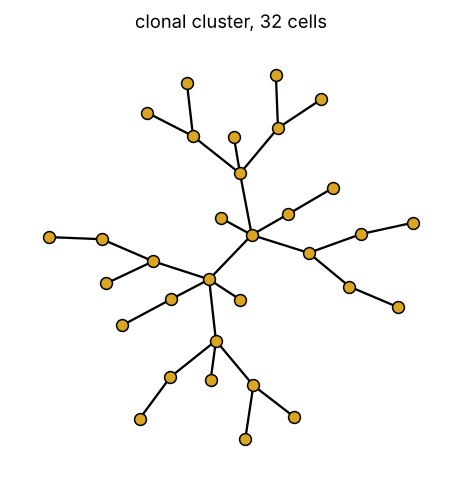

In [7]:
h = results[('settle', 'clonal')][0]
gid = np.bincount(h['final_grp']).argmax()
mem = np.nonzero(h['final_grp'] == gid)[0]
T = nx.Graph([(int(i), int(h['final_par'][i])) for i in mem if h['final_par'][i] >= 0])
plt.figure(figsize=(4, 4))
nx.draw(T, nx.kamada_kawai_layout(T), node_size=60, node_color='goldenrod', edgecolors='k', width=1.5)
plt.title(f'clonal cluster, {len(mem)} cells'); plt.savefig('figures/01_snowflake.png'); plt.show()

## Convergent at the same species
Majority composition of each evolved settling population, against the ancestor. Every replicate
reached multicellularity through the same change — the separase switched off and its sole repressed
neighbour switched on — just as independent snowflake-yeast lines repeatedly hit *ACE2*. The change is
the most accessible one-step move in the ancestral network, so selection finds it first.

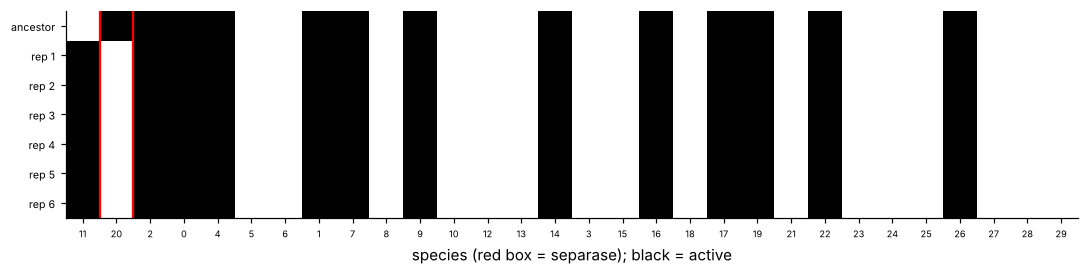

species changed relative to the ancestor, per replicate: [[np.int64(11), np.int64(20)], [np.int64(11), np.int64(20)], [np.int64(11), np.int64(20)], [np.int64(11), np.int64(20)], [np.int64(11), np.int64(20)], [np.int64(11), np.int64(20)]]
mean Hamming distance between evolved replicates: 0.0 species


In [8]:
maj = np.array([(h['final_states'].mean(0) > 0.5).astype(int) for h in results[('settle', 'clonal')]])
order = np.argsort(-np.abs(maj - s0).sum(0))
fig, ax = plt.subplots(figsize=(10, 2.6))
ax.imshow(np.vstack([s0, maj])[:, order], cmap='Greys', aspect='auto')
ax.set_yticks(range(REPS + 1)); ax.set_yticklabels(['ancestor'] + [f'rep {i+1}' for i in range(REPS)], fontsize=7)
ax.set_xticks(range(chem.N)); ax.set_xticklabels(order, fontsize=6)
ax.axvline(list(order).index(roles['sep']) - .5, c='r'); ax.axvline(list(order).index(roles['sep']) + .5, c='r')
ax.set_xlabel('species (red box = separase); black = active'); plt.tight_layout()
plt.savefig('figures/01_convergence.png'); plt.show()
print('species changed relative to the ancestor, per replicate:', [list(np.nonzero(m != s0)[0]) for m in maj])
print('mean Hamming distance between evolved replicates:',
      np.round(np.mean([np.abs(a - b).sum() for i, a in enumerate(maj) for b in maj[i + 1:]]), 1), 'species')

## How the waiting time depends on mutation supply
Larger demographic noise (smaller cells) means more frequent state switches. Settling selection on the
clonal route.

ω = 0.13: 4/6 populations, median 38 generations
ω = 0.14: 6/6 populations, median 32 generations
ω = 0.15: 6/6 populations, median 15 generations


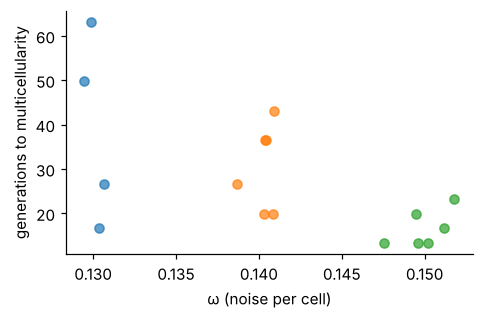

total run time: 850 s


In [9]:
omegas = [0.13, 0.14, 0.15]
extra = [om for om in omegas if om != OMEGA]
jobs = [dict(omega=om, days=DAYS, selection='settle', route='clonal', seed=500 + r)
        for om in extra for r in range(REPS)]
out2 = run_parallel(run_one, jobs, N_JOBS)
by_om = {om: out2[i * REPS:(i + 1) * REPS] for i, om in enumerate(extra)}
by_om[OMEGA] = results[('settle', 'clonal')]
plt.figure(figsize=(4.5, 3))
for i, om in enumerate(omegas):
    t = np.array([origin_time(h) for h in by_om[om]])
    plt.plot(np.full(REPS, om) + np.random.default_rng(i).normal(0, 0.001, REPS), t, 'o', alpha=.7)
    print(f'ω = {om}: {np.sum(~np.isnan(t))}/{REPS} populations, median {np.nanmedian(t):.0f} generations')
plt.xlabel('ω (noise per cell)'); plt.ylabel('generations to multicellularity')
plt.tight_layout(); plt.savefig('figures/01_waiting_time.png'); plt.show()
print(f'total run time: {time.time() - t_start:.0f} s')

## Reading the results against the review
* **Readily accessible.** Under settling selection every replicate evolves groups within a few tens of
  generations, and most do under predation; under random transfer none do, because grouped cells pay a
  growth cost.
* **Single large-effect change, repurposing.** The clonal route is one noise-driven switch that turns off
  a species already present (the ACE2 analogy); the aggregative route turns on another existing species.
* **Convergence.** Independent replicates reach groups through the same accessible switch.
* **Clonal ≠ aggregative.** Clonal clusters are made of kin; aggregates (here capped at 8 cells) are as
  related as two random cells. This is what makes clonal groups the substrate for the later challenges
  (notebook 03).

Our time scale (tens of generations) is shorter than the hundreds seen in the laboratory because we chose
a high mutation supply; the last panel shows how the waiting time scales with it.